# 02 — Fertilizer advice and quantity arithmetic

## Goal
Predict a fertilizer label, inspect illustrative N/P/K gaps, and calculate quantities from a user-entered rate.
These are three separate operations: learned classification, reference comparison and unit arithmetic.

## Data dictionary
| Columns | Meaning |
|---|---|
| Temperature, Humidity | Temperature in °C and humidity in % |
| Moisture | Reference moisture value; measurement basis is undocumented |
| Soil_Type, Crop_Type | Categorical inputs |
| Nitrogen, Phosphorous, Potassium | Numeric reference values, not verified soil-test units |
| Fertilizer_Name | Target product label |

`Phosphorous` preserves the source CSV's spelling so feature names stay consistent.
The source generates the target with if/elif nutrient rules. For example, nitrogen below 20 with
phosphorus and potassium at least 20 receives the Urea label. This creates a learnable classification
exercise; it does not prove an agronomic prescription. Crop and soil values are generated independently.

## Environment and imports

**What we do:** Locate the project and import the libraries used in this notebook.

**Why we do it:** Relative paths let this project work after it is moved or cloned. pandas handles tables, NumPy handles arrays, and Matplotlib draws graphs. The src package contains shared, readable code.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project folder or its notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import SPECS, load_data
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Project:", ROOT.name)

Project: agrisense-college-mini


**Read the output:** The printed folder should be agrisense-college-mini. In VS Code select the project's .venv Python environment as the notebook kernel. Run cells from top to bottom.

## Load and inspect data

**What we do:** Read the CSV, preview its rows, check column types and summarize numerical values.

**Why we do it:** Inspecting real file contents avoids guessing the schema. load_data also rejects missing values, duplicate rows and non-finite numerical values instead of silently changing them.

In [2]:
KIND = "fertilizer"
df = load_data(KIND)
spec = SPECS[KIND]
display(df.head())
display(df.dtypes.to_frame("Data type"))
display(df.describe().round(2))
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

,Temperature,Humidity,Moisture,Soil_Type,Crop_Type,Nitrogen,Phosphorous,Potassium,Fertilizer_Name
0,38.0,49.8,32,Red,Cotton,7,23,15,10-26-26
1,32.3,46.6,42,Loamy,Potato,16,43,30,Urea
2,27.9,74.7,28,Clayey,Potato,44,12,42,DAP
3,30.3,84.5,67,Black,Tomato,40,6,19,DAP
4,32.5,88.5,58,Sandy,Sugarcane,8,38,31,Urea


,Data type
Temperature,float64
Humidity,float64
Moisture,int64
Soil_Type,str
Crop_Type,str
Nitrogen,int64
Phosphorous,int64
Potassium,int64
Fertilizer_Name,str


,Temperature,Humidity,Moisture,Nitrogen,Phosphorous,Potassium
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,28.41,65.23,47.53,26.96,26.94,27.40
std,5.78,14.19,12.97,13.01,12.60,12.67
min,18.00,40.10,25.00,5.00,5.00,5.00
25%,23.50,53.58,37.00,16.00,16.00,17.00
50%,28.80,65.10,48.00,27.00,27.00,28.00
75%,33.50,77.50,59.00,38.00,37.00,39.00
max,38.00,90.00,69.00,49.00,49.00,49.00


Shape: (1200, 9)
Missing values: 0
Duplicate rows: 0


**Read the output:** Check that the printed columns match the data dictionary. If missing values or duplicates are introduced later, inspect their cause and document a cleaning strategy before training.

## Inspect fertilizer labels and categories

**What we do:** List soil/crop values and plot the distribution of fertilizer labels.

**Why we do it:** Category coverage defines which choices the interface supports. Unequal class counts make macro F1 useful.

Soil_Type ['Black', 'Clayey', 'Loamy', 'Red', 'Sandy']
Crop_Type ['Barley', 'Cotton', 'Groundnut', 'Maize', 'Potato', 'Pulses', 'Rice', 'Sugarcane', 'Tomato', 'Wheat']


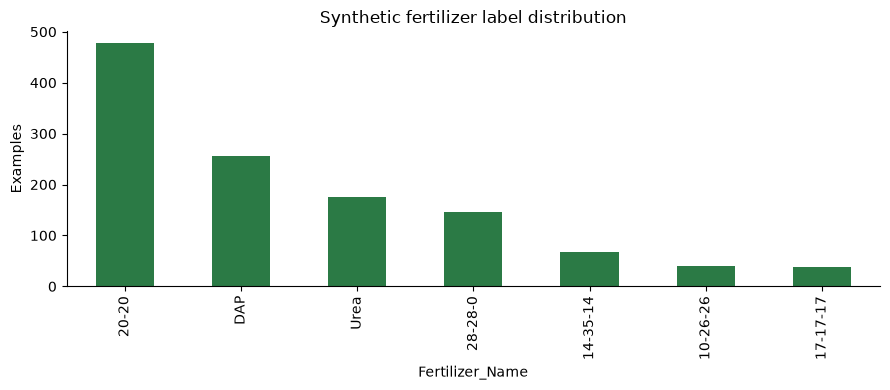

In [3]:
for name in spec["categorical"]:
    print(name, sorted(df[name].unique()))
df[spec["target"]].value_counts().plot.bar(color="#2b7a45")
plt.ylabel("Examples")
plt.title("Synthetic fertilizer label distribution")
plt.tight_layout()
plt.show()

**Read the output:** The module supports the categories shown here. Unsupported categories are rejected rather than silently treated as a known crop. Some source crop labels have no counterpart in this dataset.

## Understand one-hot encoding

**What we do:** Turn soil and crop strings into binary columns, fitting the encoder on training data only.

**Why we do it:** A tree cannot directly consume these strings. One-hot encoding avoids inventing a numerical order such as Sandy=1 and Loamy=2. A Pipeline keeps preprocessing inside each validation fold.

In [4]:
from sklearn.preprocessing import OneHotEncoder
from src.ml import split_data
X_train, X_test, y_train, y_test = split_data(KIND, df)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(X_train[spec["categorical"]])
display(pd.DataFrame(encoded[:5], columns=encoder.get_feature_names_out()))
print("Encoded shape:", encoded.shape)

,Soil_Type_Black,Soil_Type_Clayey,Soil_Type_Loamy,Soil_Type_Red,Soil_Type_Sandy,Crop_Type_Barley,Crop_Type_Cotton,Crop_Type_Groundnut,Crop_Type_Maize,Crop_Type_Potato,Crop_Type_Pulses,Crop_Type_Rice,Crop_Type_Sugarcane,Crop_Type_Tomato,Crop_Type_Wheat
0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Encoded shape: (960, 15)


**Read the output:** Each category becomes a 0/1 column. The app rejects unknown categories explicitly; the encoder's ignore option is an additional technical safeguard, not a claim that unseen crops are supported.

## Features, target and independent split

**What we do:** Select only the declared input columns, then create an 80/20 train/test split.

**Why we do it:** The test labels must not influence fitting, preprocessing or model selection. Classification is stratified to preserve class proportions. Seed 42 makes the split reproducible.

In [5]:
from src.ml import split_data, make_pipeline, train_model, predict, feature_importance
X_train, X_test, y_train, y_test = split_data(KIND, df)
print("Input columns:", X_train.columns.tolist())
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("Index overlap:", len(set(X_train.index) & set(X_test.index)))
display(X_train.head())

Input columns: ['Temperature', 'Humidity', 'Moisture', 'Nitrogen', 'Phosphorous', 'Potassium', 'Soil_Type', 'Crop_Type']
Training shape: (960, 8) Test shape: (240, 8)
Index overlap: 0


,Temperature,Humidity,Moisture,Nitrogen,Phosphorous,Potassium,Soil_Type,Crop_Type
1150,36.7,84.0,50,28,38,24,Red,Cotton
259,34.0,76.3,50,28,27,35,Sandy,Sugarcane
809,32.5,75.4,34,20,38,35,Clayey,Potato
1183,31.6,87.5,63,44,48,38,Clayey,Tomato
836,18.2,74.1,60,43,29,38,Sandy,Groundnut


**Read the output:** The overlap should be zero. X contains inputs and y contains the target. Data splitting is performed before fitting the categorical encoder. No scaling is needed for these threshold-based tree models.

## Train and choose a model

**What we do:** Compare a dummy baseline, a Decision Tree and a Random Forest on three training-data folds; fit the best non-dummy candidate and evaluate it on the held-out test set.

**Why we do it:** A baseline gives context. A Decision Tree is easy to explain; a Random Forest combines multiple trees. We choose between the two fitted approaches by validation results rather than assuming one will always win.

In [6]:
# Read src/ml.py for the shared training implementation.
# save=False reproduces results without overwriting the app's saved models.
bundle = train_model(KIND, save=False)
metrics = bundle["metrics"]
display(pd.DataFrame(metrics["comparison"]).round(4))
print("Selection metric:", metrics["cv_metric"])
print("Selected model:", metrics["selected_model"])
display(bundle["pipeline"])

,model,cv_score,cv_std
0,Dummy baseline,0.0813,0.0002
1,Decision Tree,0.9862,0.0033
2,Random Forest,0.8608,0.0183


Selection metric: macro F1 (higher is better)
Selected model: Decision Tree


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['10-26-26','14-35-14','17-17-17',...,'28-28-0','DAP','Urea']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Temperature','Humidity','Moisture',...,'Potassium','Soil_Type', 'Crop_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defa

**Read the output:** For classifiers, higher macro F1 is better. For yield regression, lower mean absolute error is better. The dummy baseline predicts the most frequent class or median yield. It is a reference, not a candidate for the final app. Cross-validation scores are separate from the held-out metrics shown next.

## Measure classification performance

**What we do:** Calculate accuracy and per-class precision, recall and F1; draw the confusion matrix.

**Why we do it:** A single percentage can hide weak classes. The confusion matrix shows which true labels are mistaken for which predicted labels. Row labels are actual classes; columns are predictions.

Test accuracy: 100.00%
Macro F1: 1.0000


,precision,recall,f1-score,support
10-26-26,1.0,1.0,1.0,8.0
14-35-14,1.0,1.0,1.0,13.0
17-17-17,1.0,1.0,1.0,8.0
20-20,1.0,1.0,1.0,95.0
28-28-0,1.0,1.0,1.0,29.0
DAP,1.0,1.0,1.0,52.0
Urea,1.0,1.0,1.0,35.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,240.0
weighted avg,1.0,1.0,1.0,240.0


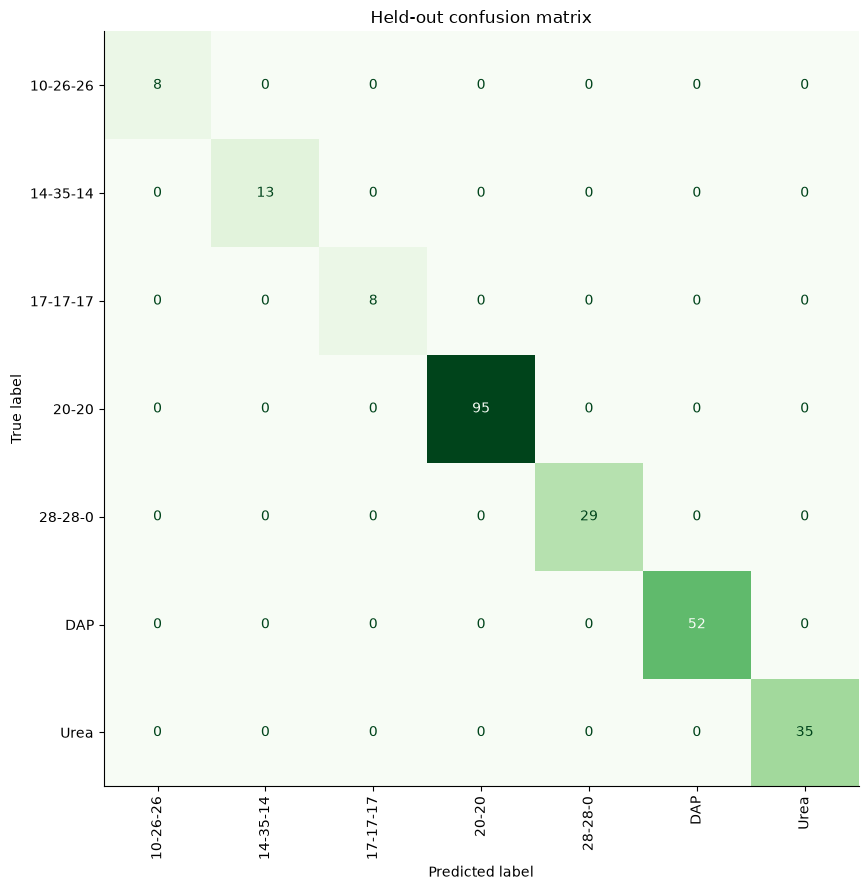

In [7]:
print(f"Test accuracy: {metrics['accuracy']:.2%}")
print(f"Macro F1: {metrics['macro_f1']:.4f}")
display(pd.DataFrame(metrics["classification_report"]).T.round(3))
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    np.array(metrics["confusion_matrix"]), display_labels=metrics["labels"]
).plot(ax=ax, cmap="Greens", xticks_rotation=90, colorbar=False)
ax.set_title("Held-out confusion matrix")
plt.tight_layout()
plt.show()

**Read the output:** Accuracy = correct predictions / all predictions. Precision = TP/(TP+FP), recall = TP/(TP+FN), and F1 is their harmonic mean. Macro F1 averages class F1 values equally; support is the number of test examples for each class. Strong diagonal counts mean more correct classifications. All scores describe this synthetic test set.

## Inspect model feature importance

**What we do:** Rank inputs by their contribution to tree impurity reduction.

**Why we do it:** This gives a starting point for discussing what the model uses. It is not a causal explanation and can be misleading for correlated or high-cardinality inputs.

,Feature,Importance
0,numeric__Phosphorous,0.463505
1,numeric__Nitrogen,0.356332
2,numeric__Potassium,0.180163
3,numeric__Moisture,0.000000
4,numeric__Temperature,0.000000
5,numeric__Humidity,0.000000
6,category__Soil_Type_Black,0.000000
7,category__Soil_Type_Clayey,0.000000
8,category__Soil_Type_Loamy,0.000000
9,category__Soil_Type_Red,0.000000


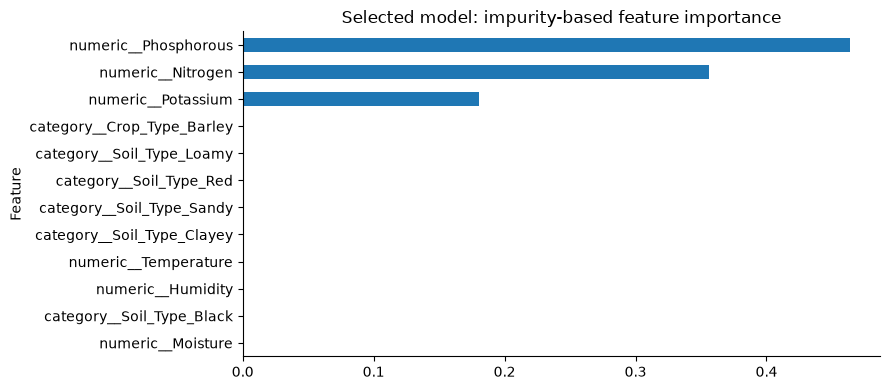

In [8]:
importance = feature_importance(bundle)
display(importance.head(12))
importance.head(12).sort_values("Importance").plot.barh(x="Feature", y="Importance", legend=False)
plt.title("Selected model: impurity-based feature importance")
plt.tight_layout()
plt.show()

**Read the output:** The prefix numeric__ identifies a numerical feature; category__ identifies an encoded category. Importance values are model-specific, not biological rules.

## Predict a fertilizer label

**What we do:** Create a sample row and examine the top-ranked product labels.

**Why we do it:** This connects the encoded training workflow to a normal form submission.

In [9]:
example = {"Temperature": 28, "Humidity": 65, "Moisture": 40, "Soil_Type": "Loamy",
           "Crop_Type": "Rice", "Nitrogen": 15, "Phosphorous": 30, "Potassium": 30}
result = predict(KIND, example, bundle)
print("Predicted label:", result["prediction"])
display(result["ranking"].head(3))

Predicted label: Urea


,Label,Model score (%)
0,Urea,100.0
1,14-35-14,0.0
2,10-26-26,0.0


**Read the output:** A Decision Tree can return 100% probability for a pure leaf. That is a property of the learned tree, not verified confidence that applying the product will help a farm.

## Compare illustrative nutrient gaps

**What we do:** Subtract each supplied value from the reference crop target and clamp negative gaps to zero.

**Why we do it:** The formula makes the calculation visible: gap = max(target - input, 0). The original project's targets are retained only as an educational comparison.

,Nutrient,Input,Illustrative target,Gap,Status
0,Nitrogen,15,40,25,Below reference
1,Phosphorus,30,30,0,At/above reference
2,Potassium,30,30,0,At/above reference


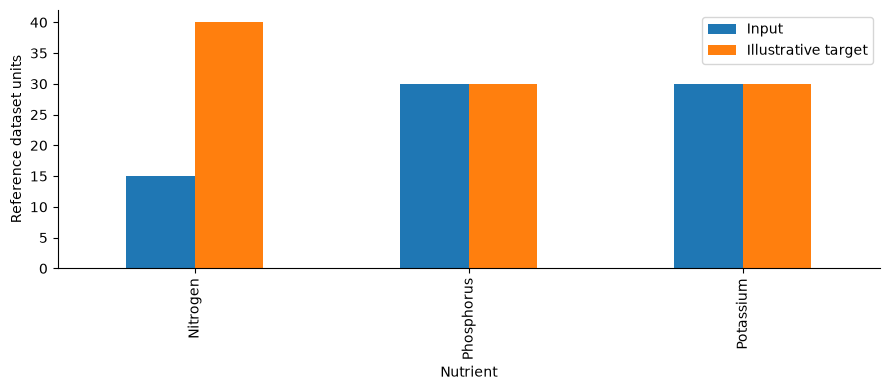

In [10]:
from src.advisory import nutrient_comparison
nutrients = nutrient_comparison("Rice", nitrogen=15, phosphorus=30, potassium=30)
display(nutrients)
nutrients.set_index("Nutrient")[["Input", "Illustrative target"]].plot.bar()
plt.ylabel("Reference dataset units")
plt.tight_layout()
plt.show()

**Read the output:** A gap of 25 means 25 reference units below the illustrative target. It does not mean 25 kg of fertilizer. Converting a soil-test value into a dose requires measurement units and validated agronomic assumptions.

## Calculate an assumed quantity and bag count

**What we do:** Multiply a user-entered rate by area, then divide by bag mass.

**Why we do it:** This keeps useful unit arithmetic without pretending to derive a field dose from undocumented nutrient values.

In [11]:
from src.advisory import fertilizer_quantity, ACRES_PER_HECTARE
rate_kg_ha = 100  # Assumed for this arithmetic example, not prescribed.
area_ha = 2
quantity = fertilizer_quantity(rate_kg_ha, area_ha)
display(pd.Series(quantity, name="Quantity"))
print("Area in acres:", round(area_ha * ACRES_PER_HECTARE, 3))

total_kg           200.0
bags_equivalent      4.0
whole_bags           4.0
Name: Quantity, dtype: float64

Area in acres: 4.942


**Read the output:** 100 kg/ha × 2 ha = 200 kg. Dividing by 50 kg per bag gives 4 bag equivalents. Whole bags are rounded upward when the equivalent count is fractional.

## Application connection and reference notes
The fertilizer page combines product rankings, the nutrient table, a bar chart and the quantity calculator.
Its optional reference panel reproduces the source's product descriptions, application examples and
organic alternatives with a clear provenance label. They are not generated or validated by the classifier.

## Limitations and extensions
Excellent test scores are expected when labels come from deterministic rules. The model mainly recovers
those rules. It does not establish whether the rules are correct for a crop, soil, location or season.
Future work would use measured soil tests with units, agronomic labels and independent regional evaluation.

## Viva questions
**Why one-hot encoding?** It represents categories without implying an ordering.

**Why a pipeline?** It fits preprocessing and the model together, including inside cross-validation.

**Why might soil have little importance?** The source label-generation rules use nutrient inputs, not soil category.

**Is the gap a fertilizer dose?** No. It is a difference between two reference values.

**Why keep quantity arithmetic separate from ML?** Its assumptions and units can be inspected independently.

**Exercise:** enter 125 kg/ha and 1.5 ha, then explain bag equivalents versus rounded whole bags.